In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

reviews = pd.read_csv('../02_Data/processed/reviews_clean.csv', parse_dates=['date'], low_memory = False)
listings = pd.read_csv('../02_Data/processed/listings_clean.csv', low_memory = False)

print(f"Total reviews: {len(reviews):,}")
print(f"Date range: {reviews['date'].min().date()} {reviews['date'].max().date()}")
print(f"Distinct listings receiving reviews: {reviews['listing_id'].nunique():,}")
print(f"% of listings with ≥1 review: {reviews['listing_id'].nunique()/len(listings)*100:.1f}%")

Total reviews: 1,033,523
Date range: 2010-10-03 2026-07-02
Distinct listings receiving reviews: 11,822
% of listings with ≥1 review: 77.3%


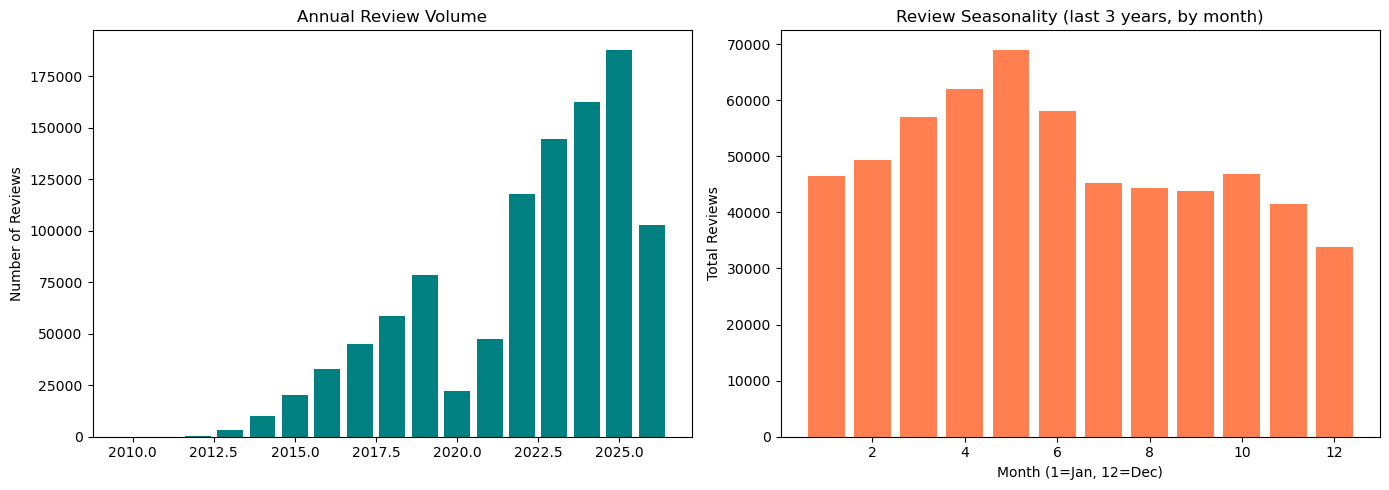

In [12]:
reviews['year'] = reviews['date'].dt.year
reviews['month'] =reviews['date'].dt.to_period('M')

annual = reviews.groupby('year').agg(
    reviews = ('id', 'count'),
    listings = ('listing_id', 'nunique')
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(annual['year'], annual['reviews'], color='teal')
ax[0].set_title('Annual Review Volume')
ax[0].set_ylabel('Number of Reviews')

recent = reviews[reviews['date'].dt.year >= reviews['date'].dt.year.max() - 3]
month_of_year = recent.groupby(recent['date'].dt.month).size()
ax[1].bar(month_of_year.index, month_of_year.values, color='coral')
ax[1].set_title('Review Seasonality (last 3 years, by month)')
ax[1].set_xlabel('Month (1=Jan, 12=Dec)')
ax[1].set_ylabel('Total Reviews')

plt.tight_layout()
plt.show()

In [13]:
reviews_per_listing = reviews.groupby('listing_id').size().rename('total_reviews')
listings_with_reviews = listings.merge(reviews_per_listing, left_on='id', right_index=True, how='left')
listings_with_reviews['total_reviews'] = listings_with_reviews['total_reviews'].fillna(0)

# Segment by review count
listings_with_reviews['review_segment'] = pd.cut(
    listings_with_reviews['total_reviews'],
    bins=[-1, 0, 10, 50, 100, 10000],
    labels=['0 (none)', '1-10', '11-50', '51-100', '100+']
)

rv_price = listings_with_reviews.groupby('review_segment').agg(
    listings=('id', 'count'),
    median_price=('price', 'median'),
    pct_entire_home=('room_type', lambda s: round((s=='Entire home/apt').mean()*100,1))
).round(1)

print("Median Price by Review Volume Segment")
display(rv_price)

Median Price by Review Volume Segment


,listings,median_price,pct_entire_home
review_segment,,,
0 (none),3548,115.0,57.2
1-10,4368,109.6,64.0
11-50,2693,193.0,72.3
51-100,1489,259.0,82.4
100+,3195,262.0,89.0
